# 04 Visualization: Smart Agriculture and Climate Resilience


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

os.makedirs("../visuals", exist_ok=True)  # create the output folder if it is missing

df = pd.read_csv("../data/processed/agri_cleaned.csv")
print(df.shape)  # expect (25432, 25)

# Rows with a usable yield: positive area and positive yield
# (Week 3 also kept zero yields; dropping them changes only the sorghum median, by 0.35 kg/ha)
valid = df[(df["plot_area_ha"] > 0) & (df["yield_kg_ha"] > 0)].copy()
print("Rows with usable yield:", len(valid))

(25432, 25)
Rows with usable yield: 25187


In [2]:
# Consistent style for every chart
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
MAIN = "#2a6f97"     # main colour for most charts
ACCENT = "#e07a1f"   # highlight colour
thousands = FuncFormatter(lambda x, pos: f"{x:,.0f}")

## Chart 1: Bar chart. Median yield by crop

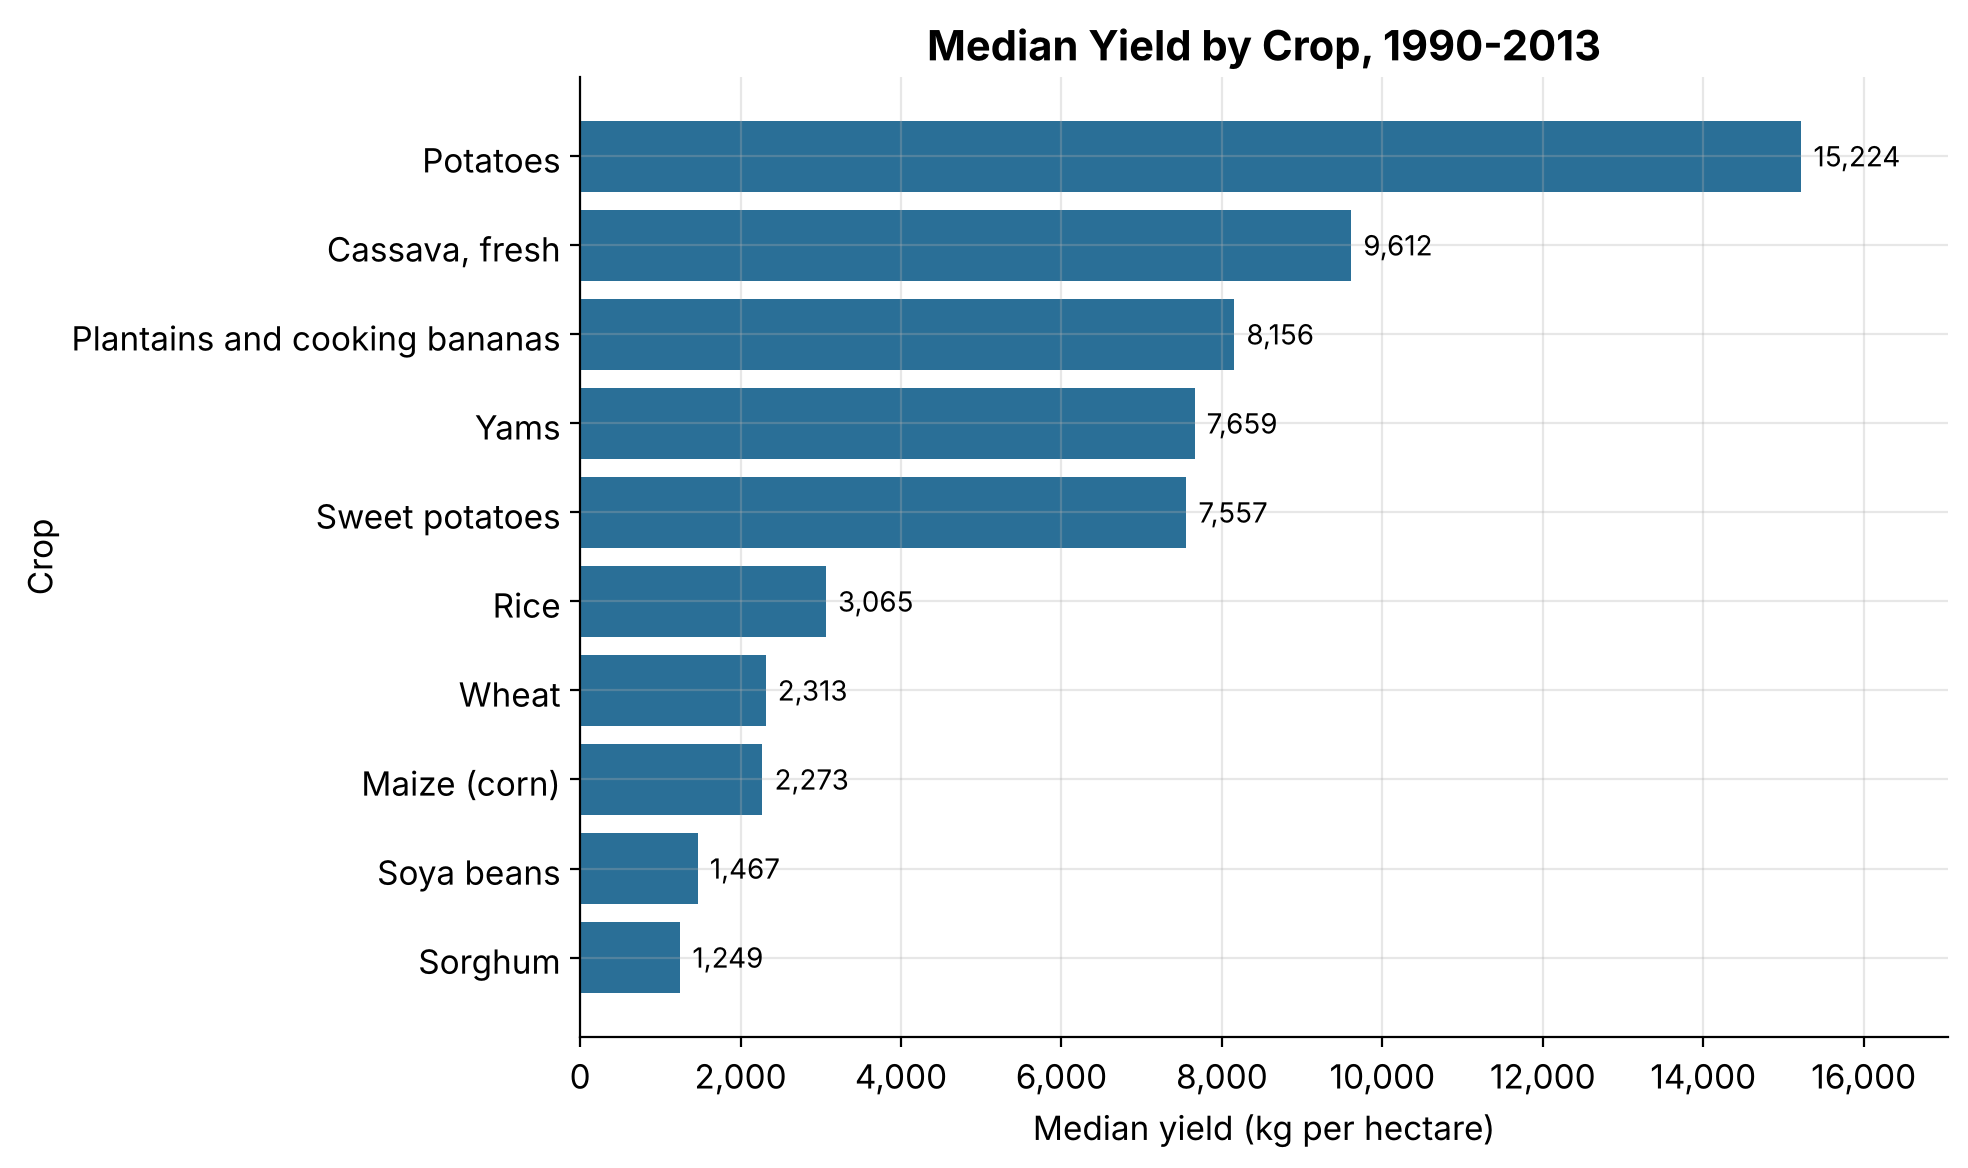

crop
Potatoes                         15224.0
Cassava, fresh                    9612.0
Plantains and cooking bananas     8156.0
Yams                              7659.0
Sweet potatoes                    7557.0
Rice                              3065.0
Wheat                             2313.0
Maize (corn)                      2273.0
Soya beans                        1467.0
Sorghum                           1249.0
Name: yield_kg_ha, dtype: float64

In [3]:
crop_median = valid.groupby("crop")["yield_kg_ha"].median().sort_values()

fig, ax = plt.subplots()
ax.barh(crop_median.index, crop_median.values, color=MAIN)
ax.set_title("Median Yield by Crop, 1990-2013")
ax.set_xlabel("Median yield (kg per hectare)")
ax.set_ylabel("Crop")
ax.xaxis.set_major_formatter(thousands)
for i, v in enumerate(crop_median.values):
    ax.text(v + 150, i, f"{v:,.0f}", va="center", fontsize=10)
ax.set_xlim(0, crop_median.max() * 1.12)
plt.tight_layout()
plt.savefig("../visuals/01_median_yield_by_crop.png", dpi=200)
plt.show()
crop_median.sort_values(ascending=False).round(0)

**Figure 1. Median yield by crop.** Potatoes lead at about 15,224 kg/ha, followed by cassava (9,612) and plantains (8,156), while sorghum (1,249) and soya beans (1,467) are lowest. Root and tuber crops yield far more weight per hectare than grains and pulses. This matters because a high yield in kg/ha does not mean a crop is more valuable or nutritious per kilogram, so crops should only be compared like-for-like. Caveat: medians pool all countries and years, and each crop is grown in a different mix of countries.

## Chart 2: Line chart. Staple crop yields over time

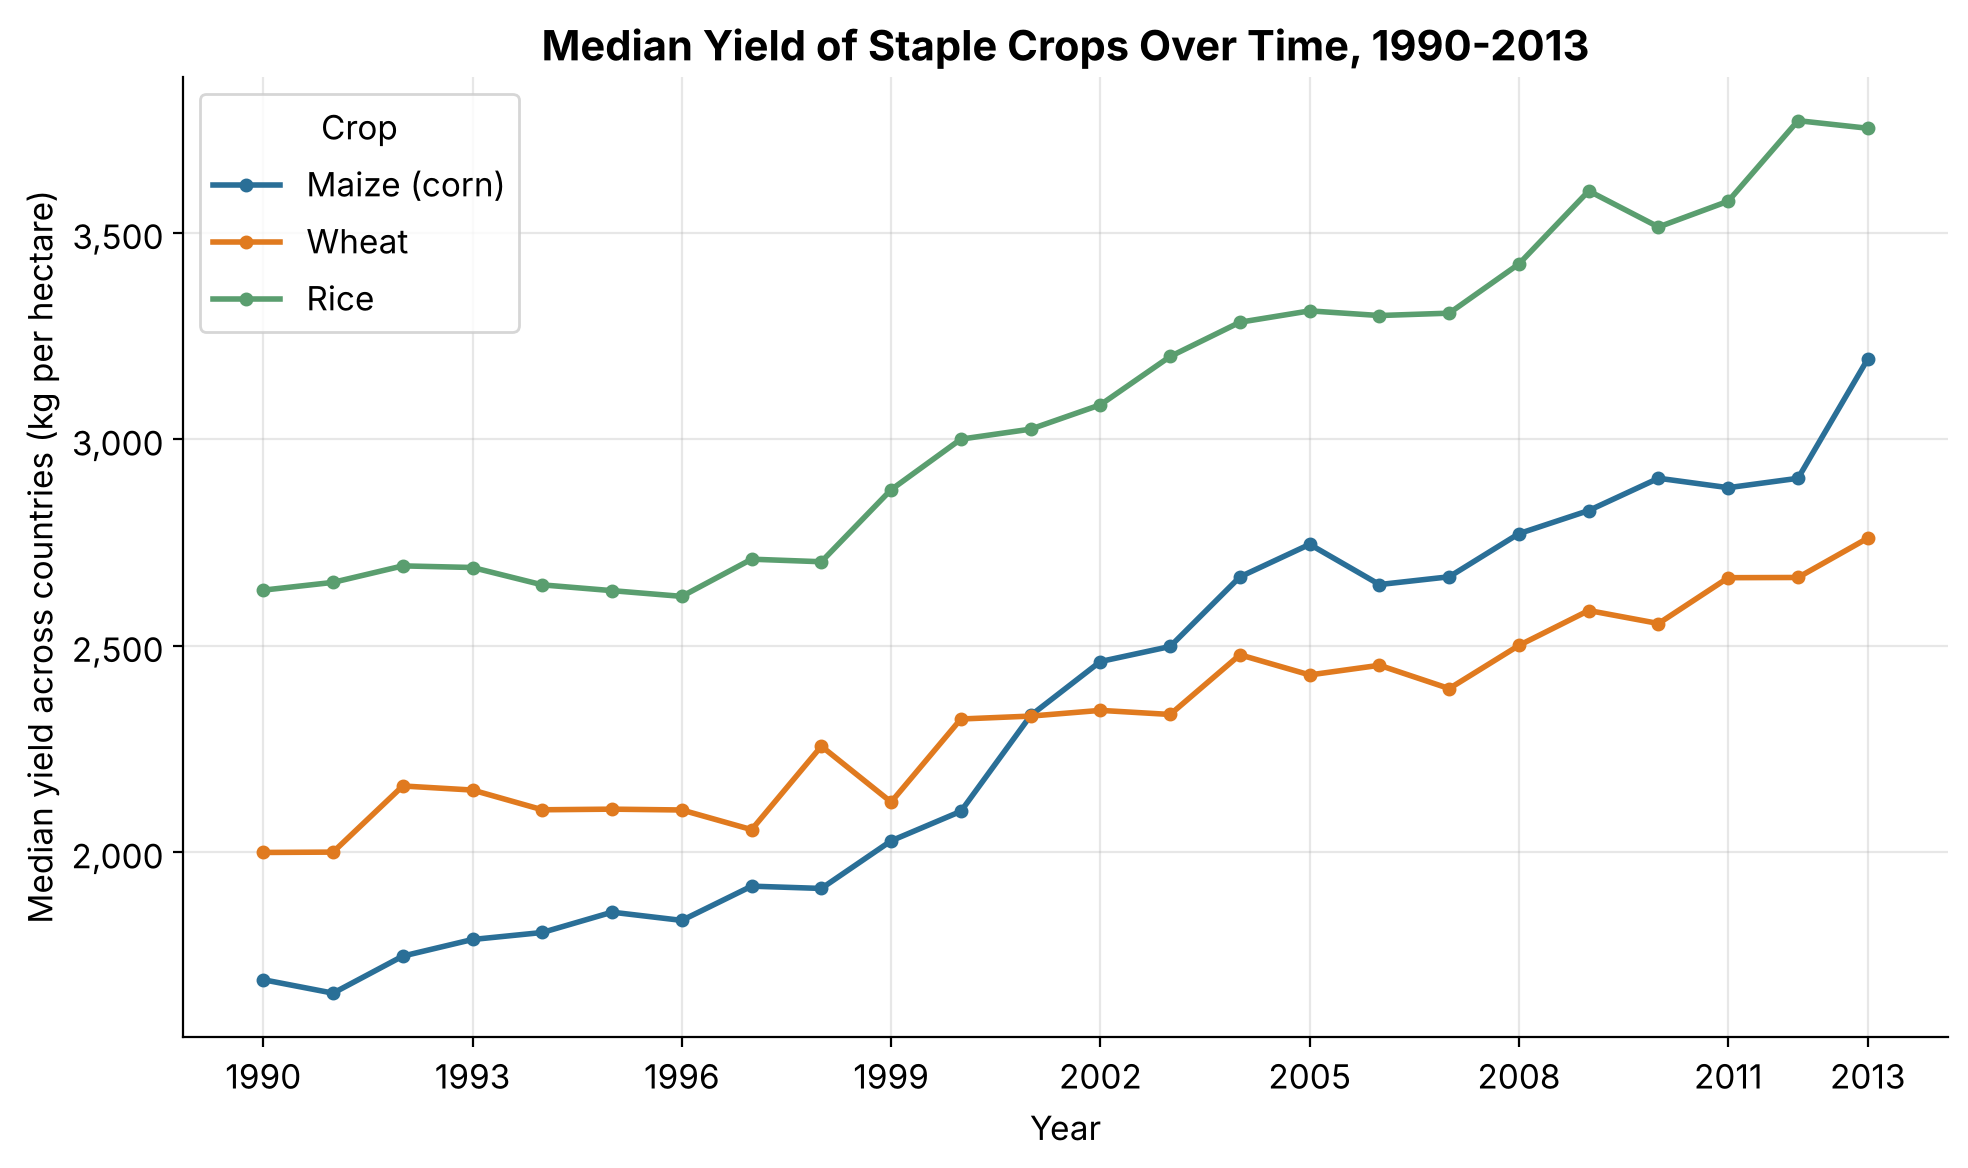

crop,Maize (corn),Rice,Wheat
year,,,
1990,1691.0,2634.0,1999.0
2013,3194.0,3753.0,2760.0


In [4]:
staples = ["Maize (corn)", "Wheat", "Rice"]
trend = (valid[valid["crop"].isin(staples)]
         .groupby(["year", "crop"])["yield_kg_ha"].median()
         .unstack("crop"))

fig, ax = plt.subplots()
colours = {"Maize (corn)": MAIN, "Wheat": ACCENT, "Rice": "#5a9e6f"}
for crop in staples:
    ax.plot(trend.index, trend[crop], marker="o", markersize=4, linewidth=2,
            label=crop, color=colours[crop])
ax.set_title("Median Yield of Staple Crops Over Time, 1990-2013")
ax.set_xlabel("Year")
ax.set_ylabel("Median yield across countries (kg per hectare)")
ax.yaxis.set_major_formatter(thousands)
ax.set_xticks(list(range(1990, 2014, 3)) + [2013])
ax.legend(title="Crop")
plt.tight_layout()
plt.savefig("../visuals/02_staple_yield_trend.png", dpi=200)
plt.show()
trend.loc[[1990, 2013]].round(0)

**Figure 2. Staple crop yields over time.** All three staples ended higher in 2013 than in 1990: maize rose about 89% (1,691 to 3,194 kg/ha), rice about 42% (2,634 to 3,753) and wheat about 38% (1,999 to 2,760), with rice and wheat fairly flat until the late 1990s. Rising yield per hectare matters for food security because more food can come from the same land. Caveat: the line is the median across whichever countries reported each year, so the set of countries is not identical every year, and the chart shows the trend but not its causes.

## Chart 3: Histogram. Distribution of maize yields

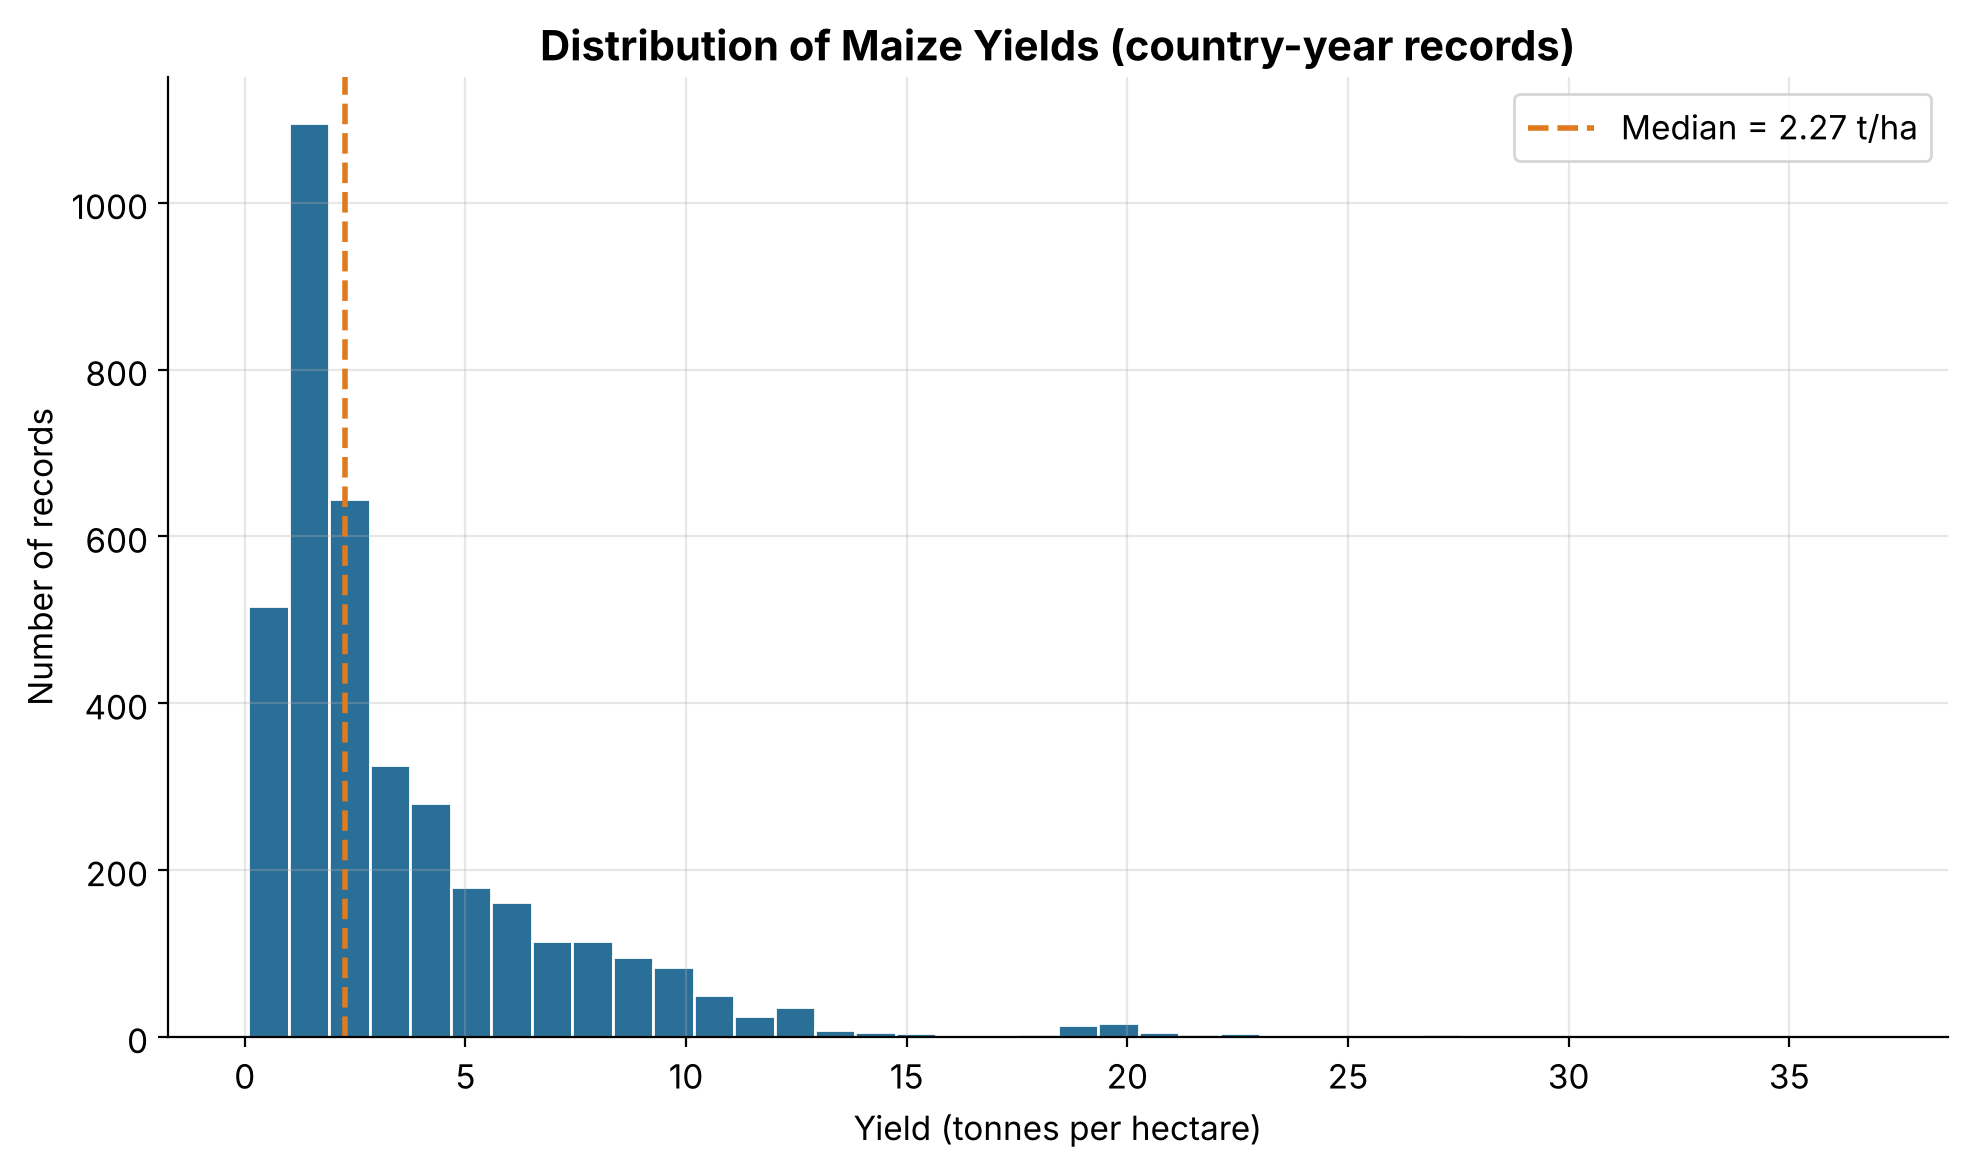

count    3804.00
mean        3.62
std         3.64
min         0.08
25%         1.37
50%         2.27
75%         4.62
max        36.76
Name: yield_t_ha, dtype: float64

In [5]:
maize = valid[valid["crop"] == "Maize (corn)"]
med = maize["yield_t_ha"].median()

fig, ax = plt.subplots()
ax.hist(maize["yield_t_ha"], bins=40, color=MAIN, edgecolor="white")
ax.axvline(med, color=ACCENT, linewidth=2, linestyle="--", label=f"Median = {med:.2f} t/ha")
ax.set_title("Distribution of Maize Yields (country-year records)")
ax.set_xlabel("Yield (tonnes per hectare)")
ax.set_ylabel("Number of records")
ax.legend()
plt.tight_layout()
plt.savefig("../visuals/03_maize_yield_histogram.png", dpi=200)
plt.show()
maize["yield_t_ha"].describe().round(2)

**Figure 3. Distribution of maize yields.** Most records sit at low yields, with a median near 2.3 t/ha, and a long tail of high-yield records stretches to the right. The mean (about 3.6 t/ha) is well above the median because of that tail, which is why this project reports medians. Caveat: each bar counts country-year records, so countries with a longer reporting history appear more often, and the high tail includes outliers that were flagged but kept in Week 3.

## Chart 4: Category share. Share of total production by crop (horizontal bar)
A pie chart would need ten slices, and several are tiny (under 2%), which makes them hard to read and compare. A sorted horizontal bar chart is clearer for ten categories.

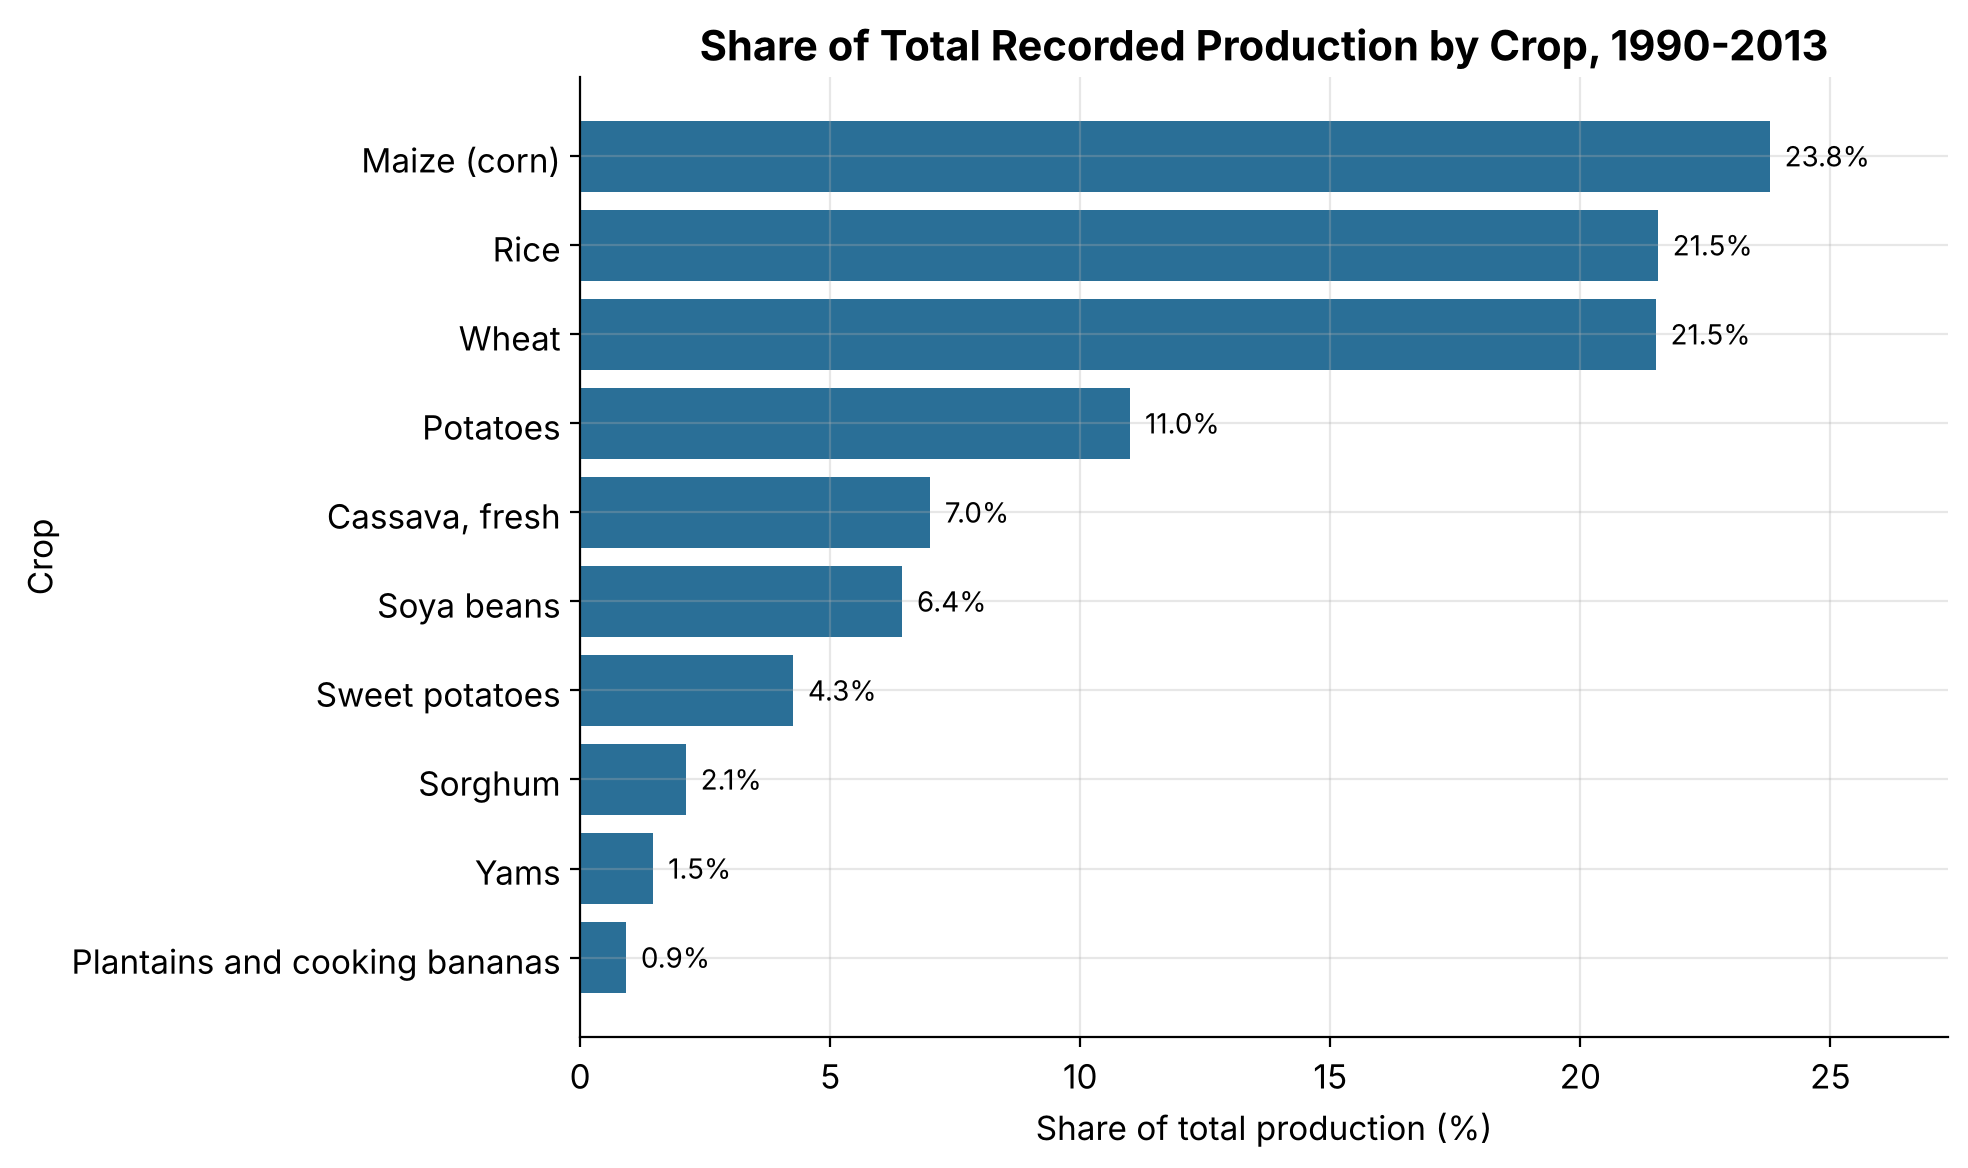

crop
Maize (corn)                     23.8
Rice                             21.5
Wheat                            21.5
Potatoes                         11.0
Cassava, fresh                    7.0
Soya beans                        6.4
Sweet potatoes                    4.3
Sorghum                           2.1
Yams                              1.5
Plantains and cooking bananas     0.9
Name: production_tonnes, dtype: float64

In [6]:
share = (df.groupby("crop")["production_tonnes"].sum()
         / df["production_tonnes"].sum() * 100).sort_values()

fig, ax = plt.subplots()
ax.barh(share.index, share.values, color=MAIN)
ax.set_title("Share of Total Recorded Production by Crop, 1990-2013")
ax.set_xlabel("Share of total production (%)")
ax.set_ylabel("Crop")
for i, v in enumerate(share.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=10)
ax.set_xlim(0, share.max() * 1.15)
plt.tight_layout()
plt.savefig("../visuals/04_production_share_by_crop.png", dpi=200)
plt.show()
share.sort_values(ascending=False).round(1)

**Figure 4. Share of production by crop.** Maize (23.8%), rice (21.5%) and wheat (21.5%) together make up about two thirds of all recorded production tonnage, while plantains and yams are each under 2%. This shows that global output is concentrated in a few staple grains, so changes in their yields affect the total far more than any other crop. A horizontal bar is used instead of a pie because ten slices with several very small shares are hard to compare. Caveat: shares are by weight in tonnes, so heavy root crops look larger than they would by calories or value, and the totals cover only the countries reported in FAOSTAT.

## Chart 5: Scatter plot. Rainfall against maize yield

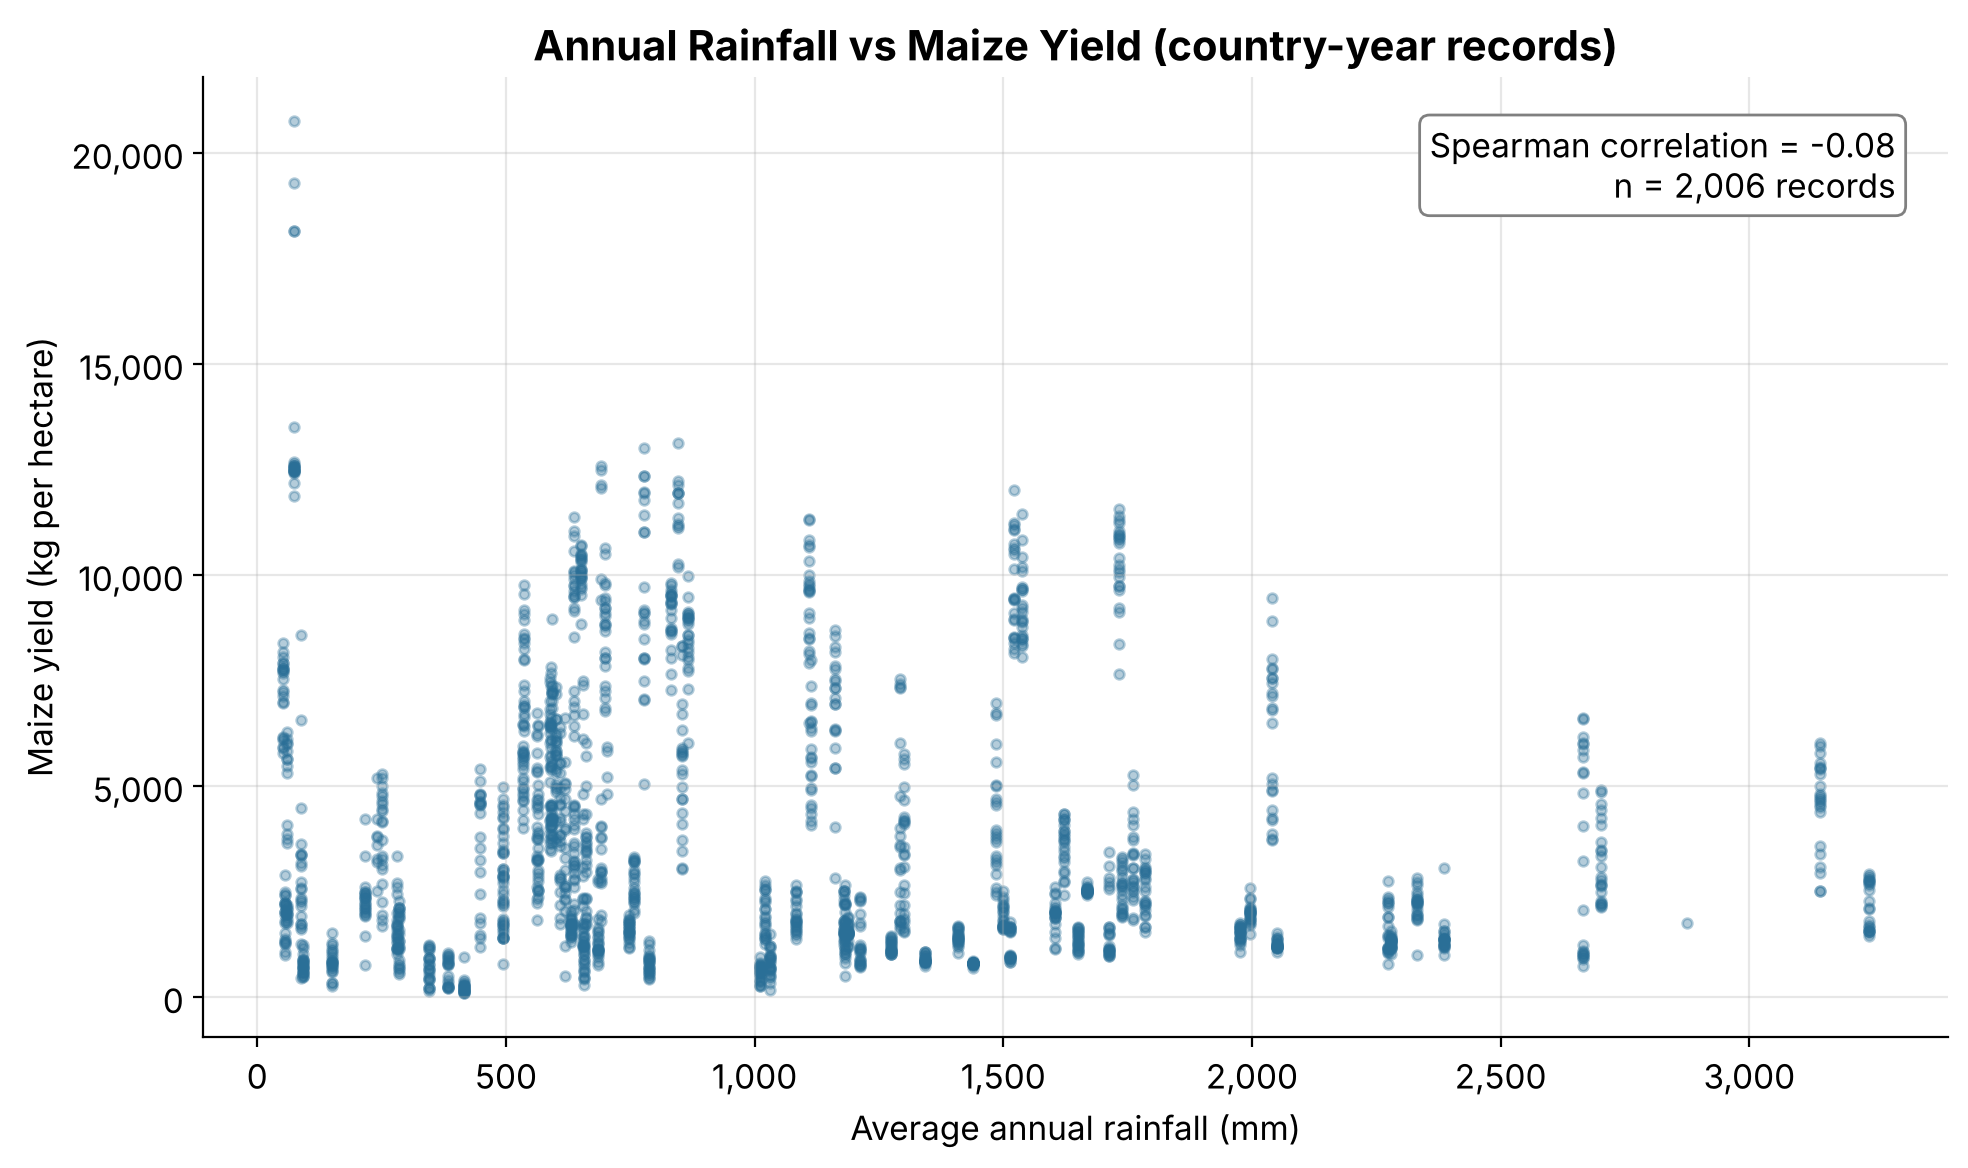

2006 -0.08


In [7]:
rain = valid[(valid["crop"] == "Maize (corn)")].dropna(subset=["rainfall_mm"])
rho = rain[["rainfall_mm", "yield_kg_ha"]].corr(method="spearman").iloc[0, 1]

fig, ax = plt.subplots()
ax.scatter(rain["rainfall_mm"], rain["yield_kg_ha"], s=12, alpha=0.35, color=MAIN)
ax.set_title("Annual Rainfall vs Maize Yield (country-year records)")
ax.set_xlabel("Average annual rainfall (mm)")
ax.set_ylabel("Maize yield (kg per hectare)")
ax.xaxis.set_major_formatter(thousands)
ax.yaxis.set_major_formatter(thousands)
ax.text(0.97, 0.95, f"Spearman correlation = {rho:.2f}\nn = {len(rain):,} records",
        transform=ax.transAxes, ha="right", va="top",
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="grey"))
plt.tight_layout()
plt.savefig("../visuals/05_rainfall_vs_maize_yield.png", dpi=200)
plt.show()
print(len(rain), round(rho, 3))

**Figure 5. Rainfall against maize yield.** The points form a broad cloud with no clear upward or downward pattern, and the Spearman correlation is close to zero (about -0.08). In this data, higher rainfall alone does not predict higher maize yield, which warns against using rainfall as a simple yield forecast. Caveat: rainfall is one national average per country, so each vertical stripe is one country repeated across years, and the average hides regional and seasonal differences. Other factors such as irrigation, soil and inputs also vary, and only 2,006 maize records have climate data because about half the countries are missing it.

## Chart check: confirm all five PNG files were exported

In [8]:
files = sorted(f for f in os.listdir("../visuals") if f.endswith(".png"))
print(len(files), "charts exported:")
for f in files:
    print(" -", f)

5 charts exported:
 - 01_median_yield_by_crop.png
 - 02_staple_yield_trend.png
 - 03_maize_yield_histogram.png
 - 04_production_share_by_crop.png
 - 05_rainfall_vs_maize_yield.png
